# 11 · Fire & Smoke Digital Twin – fire incident calls (13 US cities)

**Utility for the City Brain: medium** · Domain: fire calls · Incident types: `fire`

> 331,616 real fire-department calls (type, position, time) collected from public feeds: realistic fire call categories and rates, including many alarms that are not fires.

| | |
|---|---|
| **Source** | GitHub `UrbanInfoLab/FireIncidentData` (paper: arXiv:2305.18313) |
| **Licence** | Public repository without an explicit licence: not redistributed here |
| **In this repo** | No data. Outputs below were produced on the full clone |
| **Get it** | `git clone https://github.com/UrbanInfoLab/FireIncidentData` (files `api/v1/{City}/{Y}/{M}/{D}/FireMap.json`) |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

One JSON file per city per day, in RSS form: each item has a `title` (`"98 - Structure Fire Reported"`), `link` (map position), `description` (`"address | agency | time"`), `pubDate`. Despite the project name, there are **no smoke or sensor readings**.

In [2]:
root = Path(path('fire/fire-incident-calls/api/v1'))
rows, empty = [], 0
for f in root.glob('*/*/*/*/FireMap.json'):
    try: items = json.load(open(f))['rss']['channel'].get('item', [])
    except Exception: empty += 1; continue
    if isinstance(items, dict): items = [items]
    if not items: empty += 1
    city = f.parts[-5]
    for it in items:
        rows.append((city, it.get('title', ''), it.get('pubDate', ''), (it.get('guid') or {}).get('#text', '')))
calls = pd.DataFrame(rows, columns=['city', 'title', 'pubDate', 'pos']).drop_duplicates()
calls['type'] = calls.title.str.replace(r'^\s*\S+\s*-\s*', '', regex=True).str.strip()
print(f"{len(calls):,} unique calls, {calls.city.nunique()} cities, {empty:,} empty daily files"); calls.head()

331,616 unique calls, 13 cities, 3,493 empty daily files


,city,title,pubDate,pos,type
0,Seattle,Level 2 Fire,"Thu, 14 Sep 2023 00:10:22 CDT","32.707518,-117.155015",Level 2 Fire
1,Seattle,Level 2 Fire,"Thu, 14 Sep 2023 00:55:24 CDT","32.635812,-117.079636",Level 2 Fire
2,Seattle,Level 1 Fire,"Thu, 14 Sep 2023 01:20:26 CDT","32.724879,-117.17069",Level 1 Fire
3,Seattle,Level 2 Fire,"Thu, 14 Sep 2023 01:45:19 CDT","32.641347,-117.08896",Level 2 Fire
4,Seattle,Level 2 Fire,"Thu, 14 Sep 2023 01:50:21 CDT","32.707612,-117.160091",Level 2 Fire


In [3]:
calls.city.value_counts().to_frame('calls')

,calls
city,
Seattle,95974
Houston,81118
Dallas,34643
SanAntonio,29791
Milwaukee,21216
Austin,18812
Riverside,14121
Miami,12857
Portland,7602


In [4]:
calls.type.value_counts().head(15).to_frame('calls')

,calls
type,
Level 2 Fire,78505
FIRE EVENT,35403
Automatic Fire Alarm,18209
Level 1 Fire,17427
FIRE ONLY,14984
Fire Event,13748
FIRE ALARM,8818
Fire Call - Transfer,8688
Report of Fire,7253


Calls whose type is an alarm (not a confirmed fire): 43,363 (13 %)


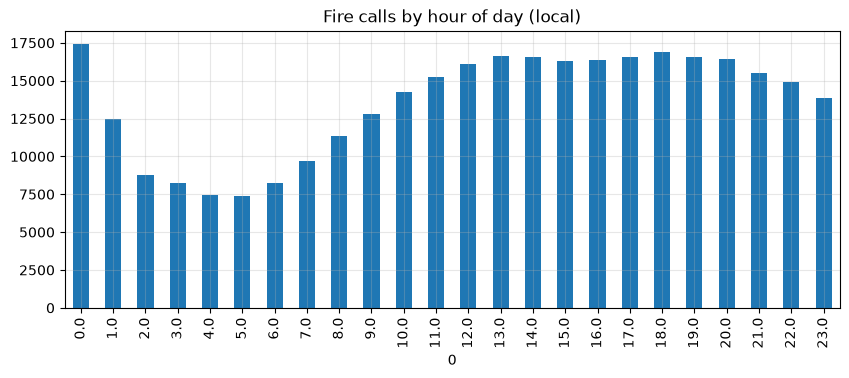

In [5]:
alarm = calls.type.str.contains('alarm', case=False)
print(f"Calls whose type is an alarm (not a confirmed fire): {alarm.sum():,} ({alarm.mean() * 100:.0f} %)")
hour = pd.to_numeric(calls.pubDate.str.extract(r'(\d{2}):\d{2}:\d{2}')[0], errors='coerce')
hour.value_counts().sort_index().plot(kind='bar', title='Fire calls by hour of day (local)'); plt.show()

## 2. What it means for the City Brain

| Use | How |
|---|---|
| **Mock** | Realistic fire call types and hourly rates for `brain/internal/call` (low at 3–6h, plateau 11–21h) |
| **Detect** | Many calls are automatic alarms, not fires: supports "fire call **and** sensor signal" before high confidence |
| **Score** | Realistic call volumes per city per day |
| **Scenarios** | Car fires after crashes ("MVC – fire"): a real accident → fire link |

**Limits:** no sensor data, no outcome (was it a real fire?), feeds differ by city, collection gaps (empty days).